(k,accuracy) {'k': 42.0, 'n_correct': 34160.0, 'n_eval': 52478.0, 'accuracy_percent': 65.09394412896833}


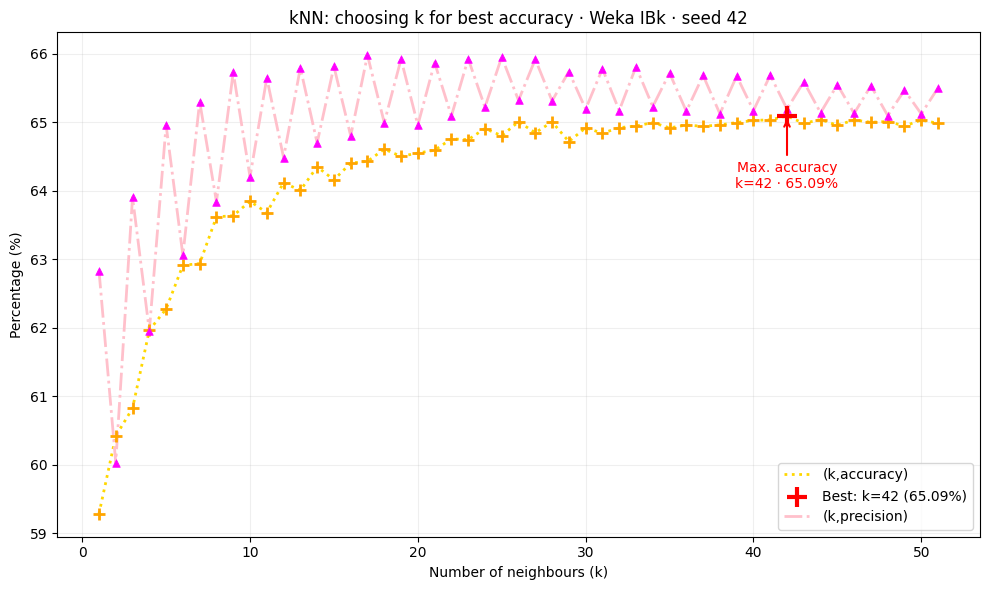

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv('/accuracy_precision_vs_k.csv')
new = raw.groupby('k', as_index=False)[['n_correct', 'n_eval']].sum()
new['accuracy_percent'] = 100 * new.n_correct / new.n_eval
new.to_csv('accuracy_sin_has_awards.csv', index=False)
raw2 = pd.read_csv('/accuracy_precision_vs_k.csv')
new2 = raw2.groupby('k', as_index=False)[['k', 'precision_percent']].sum()
fig, ax = plt.subplots(figsize=(10, 6))
for df, label in [(new, '(k,accuracy)')]:
    ax.plot(df.k, df.accuracy_percent, ls=':', color='gold',
            linewidth=2, zorder=2, label=label)
    ax.scatter(df.k, df.accuracy_percent, marker='+', color='orange',
               s=80, linewidths=2, zorder=3)
    best = df.loc[df.accuracy_percent.idxmax()]
    ax.scatter(best.k, best.accuracy_percent, marker='+', color='red',
               s=200, linewidths=3, zorder=5,
               label=f'Best: k={int(best.k)} ({best.accuracy_percent:.2f}%)')
    y_range = df.accuracy_percent.max() - df.accuracy_percent.min()
    offset = (y_range if y_range > 0 else 1) * 0.15
    ax.annotate(f'Max. accuracy\nk={int(best.k)} · {best.accuracy_percent:.2f}%',
                xy=(best.k, best.accuracy_percent),
                xytext=(best.k, best.accuracy_percent - offset),
                ha='center', va='center', fontsize=10, color='red',
                arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
                zorder=-6)
    print(label, best.to_dict())
for df2, label2 in [(new2, '(k,precision)')]:
    ax.plot(df2.k, df2.precision_percent, ls='-.', color='pink',
            linewidth=2, zorder=2, label=label2)
    ax.scatter(df2.k, df2.precision_percent, marker='^', color='magenta',
               s=30, linewidths=0.5, zorder=3)
ax.set(title='kNN: choosing k for best accuracy · Weka IBk · seed 42',
       xlabel='Number of neighbours (k)', ylabel='Percentage (%)')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig('/comparacion.svg', dpi=300)


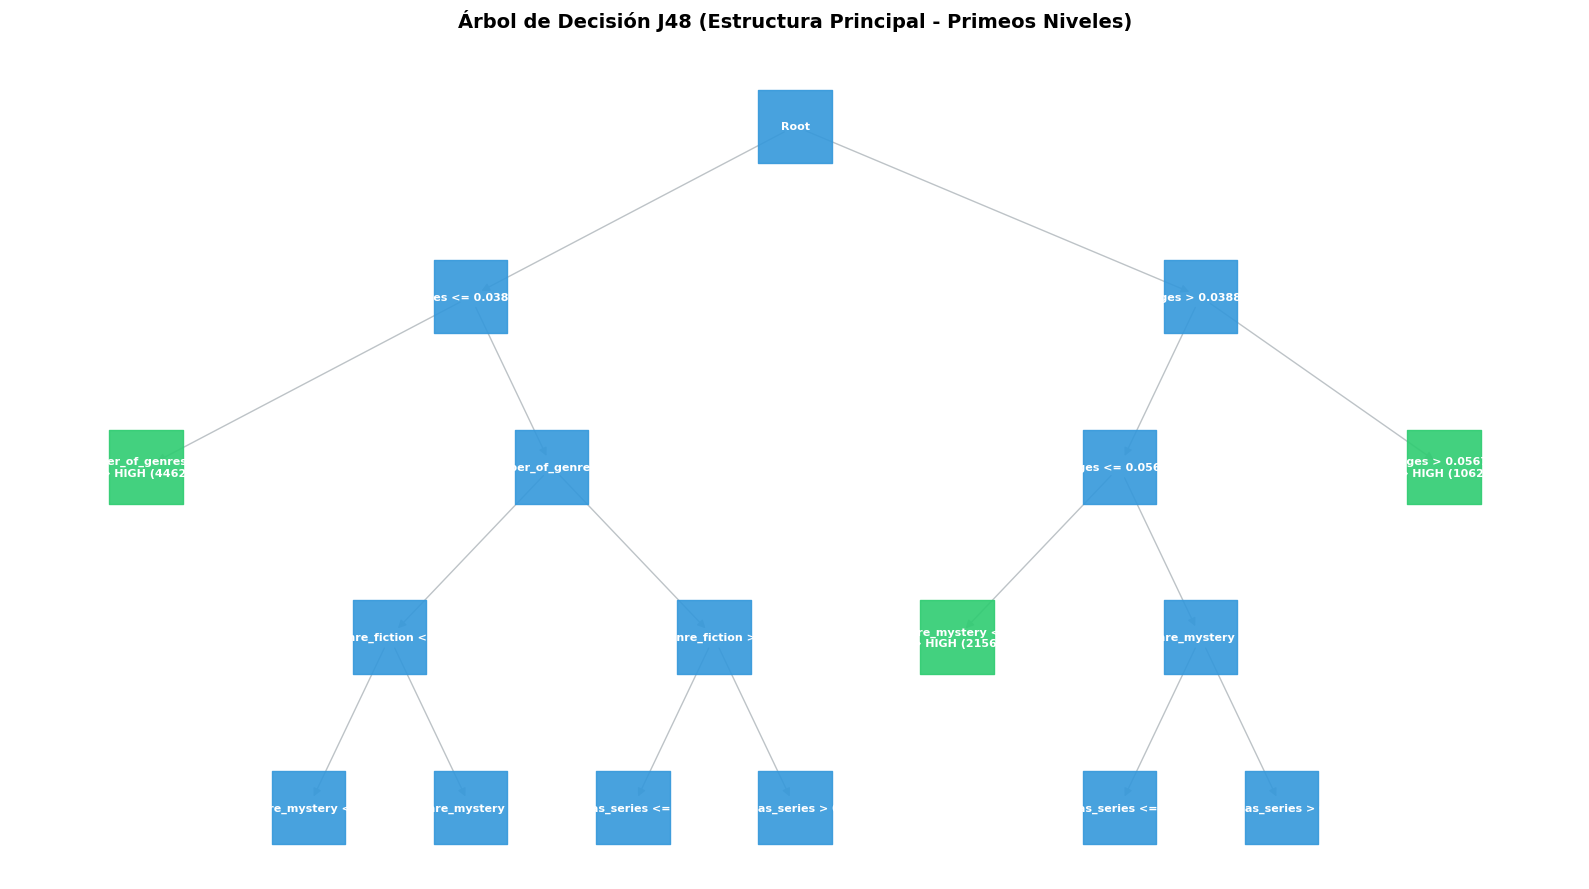

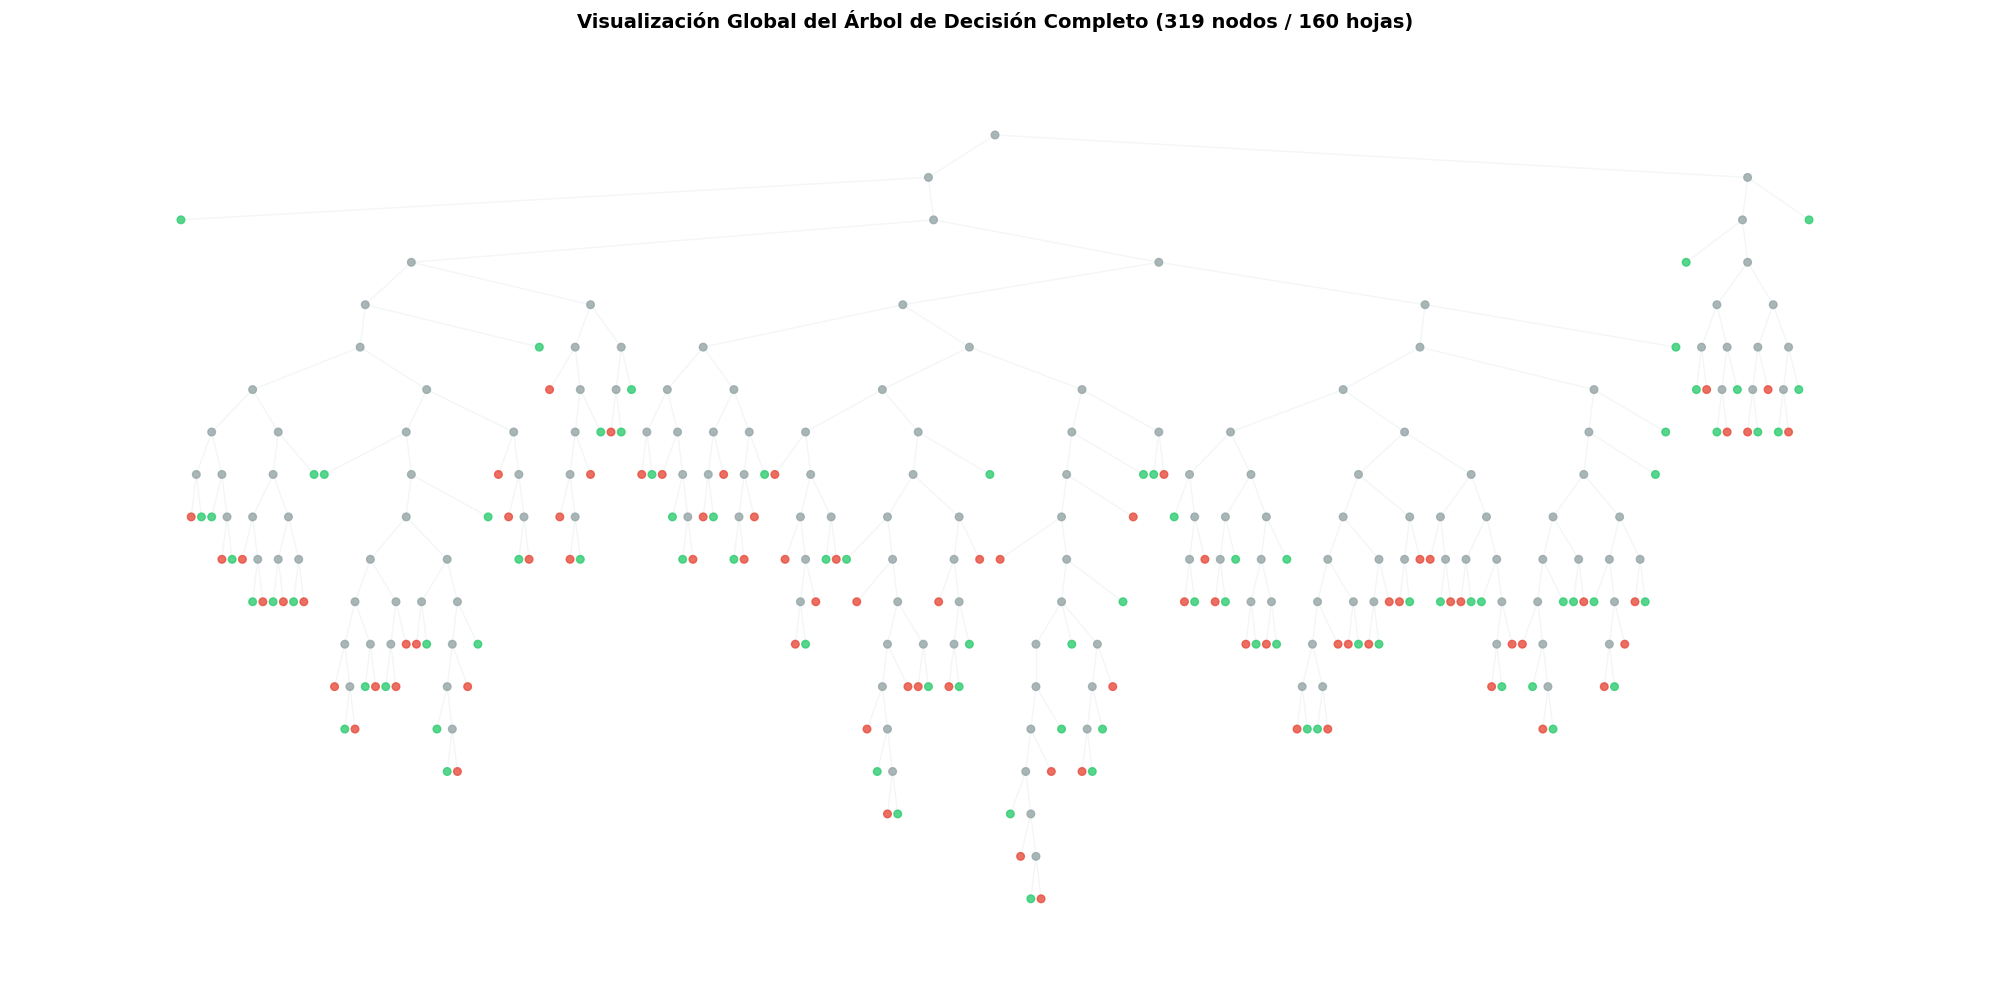

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import re

# 1. Cadena de reglas en formato J48 extraída del árbol HTML
raw_tree_data = """pages <= 0.038844
|number_of_genres <= 0: high_rating (4462.0/1142.0)
|number_of_genres > 0
||genre_fiction <= 0
|||genre_mystery <= 0
||||pages <= 0.020234
|||||title_length <= 0.072
||||||has_series <= 0
|||||||format_ebook <= 0
||||||||number_of_genres <= 0.6: low_rating (766.0/350.0)
||||||||number_of_genres > 0.6: high_rating (673.0/308.0)
|||||||format_ebook > 0
||||||||number_of_genres <= 0.1: high_rating (71.0/23.0)
||||||||number_of_genres > 0.1
|||||||||pages <= 0.016174: low_rating (182.0/60.0)
|||||||||pages > 0.016174: high_rating (60.0/22.0)
||||||has_series > 0
|||||||pages <= 0.006564
||||||||number_of_genres <= 0.1
|||||||||format_ebook <= 0: low_rating (24.0)
|||||||||format_ebook > 0
||||||||||pages <= 0.004737: high_rating (3.0)
||||||||||pages > 0.004737: low_rating (3.0/1.0)
||||||||number_of_genres > 0.1
|||||||||format_ebook <= 0
||||||||||pages <= 0.004196: high_rating (21.0/3.0)
||||||||||pages > 0.004196: low_rating (18.0/7.0)
|||||||||format_ebook > 0
||||||||||title_length <= 0.06: high_rating (107.0/52.0)
||||||||||title_length > 0.06: low_rating (34.0/9.0)
|||||||pages > 0.006564: high_rating (1314.0/493.0)
|||||title_length > 0.072
||||||title_length <= 0.38
|||||||has_series <= 0: high_rating (3758.0/1460.0)
|||||||has_series > 0
||||||||number_of_genres <= 0.5
|||||||||pages <= 0.013264
||||||||||format_ebook <= 0
|||||||||||pages <= 0.006632
||||||||||||number_of_genres <= 0.1: low_rating (35.0/3.0)
||||||||||||number_of_genres > 0.1
|||||||||||||pages <= 0.002301: high_rating (4.0)
|||||||||||||pages > 0.002301: low_rating (16.0/5.0)
|||||||||||pages > 0.006632
||||||||||||number_of_genres <= 0.4: high_rating (67.0/29.0)
||||||||||||number_of_genres > 0.4: low_rating (10.0/2.0)
||||||||||format_ebook > 0
|||||||||||number_of_genres <= 0.4
||||||||||||pages <= 0.012384: high_rating (45.0/14.0)
||||||||||||pages > 0.012384: low_rating (6.0/1.0)
|||||||||||number_of_genres > 0.4: low_rating (6.0/1.0)
|||||||||pages > 0.013264
||||||||||format_ebook <= 0
|||||||||||title_length <= 0.088: low_rating (14.0/5.0)
|||||||||||title_length > 0.088: high_rating (74.0/19.0)
||||||||||format_ebook > 0
|||||||||||title_length <= 0.116
||||||||||||title_length <= 0.104
|||||||||||||number_of_genres <= 0.3: high_rating (15.0/1.0)
|||||||||||||number_of_genres > 0.3
||||||||||||||pages <= 0.016444: high_rating (5.0/2.0)
||||||||||||||pages > 0.016444: low_rating (2.0)
||||||||||||title_length > 0.104: low_rating (4.0)
|||||||||||title_length > 0.116: high_rating (11.0)
||||||||number_of_genres > 0.5: high_rating (533.0/155.0)
||||||title_length > 0.38
|||||||format_ebook <= 0: low_rating (154.0/69.0)
|||||||format_ebook > 0
||||||||title_length <= 0.424: low_rating (7.0)
||||||||title_length > 0.424
|||||||||title_length <= 0.448: high_rating (5.0)
|||||||||title_length > 0.448: low_rating (17.0/6.0)
||||pages > 0.020234: high_rating (6445.0/2218.0)
|||genre_mystery > 0
||||has_series <= 0
|||||format_ebook <= 0: low_rating (179.0/67.0)
|||||format_ebook > 0
||||||number_of_genres <= 0.5
|||||||number_of_genres <= 0.2
||||||||number_of_genres <= 0.1: low_rating (7.0/2.0)
||||||||number_of_genres > 0.1
|||||||||title_length <= 0.084: low_rating (2.0)
|||||||||title_length > 0.084: high_rating (6.0/1.0)
|||||||number_of_genres > 0.2: low_rating (12.0/1.0)
||||||number_of_genres > 0.5: high_rating (26.0/9.0)
||||has_series > 0
|||||format_ebook <= 0
||||||title_length <= 0.08: low_rating (185.0/88.0)
||||||title_length > 0.08: high_rating (64.0/17.0)
|||||format_ebook > 0: high_rating (158.0/47.0)
||genre_fiction > 0
|||has_series <= 0
||||pages <= 0.007038
|||||pages <= 0.005143
||||||genre_mystery <= 0
|||||||title_length <= 0.028: low_rating (60.0/28.0)
|||||||title_length > 0.028: high_rating (579.0/175.0)
||||||genre_mystery > 0
|||||||pages <= 0.000812: low_rating (18.0/2.0)
|||||||pages > 0.000812
||||||||format_ebook <= 0: high_rating (37.0/16.0)
||||||||format_ebook > 0
|||||||||pages <= 0.002301: high_rating (5.0/1.0)
|||||||||pages > 0.002301: low_rating (7.0/1.0)
|||||pages > 0.005143
||||||title_length <= 0.12
|||||||number_of_genres <= 0.9
||||||||title_length <= 0.028: low_rating (6.0)
||||||||title_length > 0.028: high_rating (74.0/32.0)
|||||||number_of_genres > 0.9: low_rating (193.0/75.0)
||||||title_length > 0.12
|||||||number_of_genres <= 0.6
||||||||title_length <= 0.168
|||||||||title_length <= 0.144: high_rating (7.0/1.0)
|||||||||title_length > 0.144: low_rating (2.0)
||||||||title_length > 0.168: low_rating (12.0/4.0)
|||||||number_of_genres > 0.6: high_rating (44.0/11.0)
||||pages > 0.007038
|||||format_ebook <= 0
||||||title_length <= 0.132
|||||||pages <= 0.029641: low_rating (9336.0/2574.0)
|||||||pages > 0.029641
||||||||title_length <= 0.052
|||||||||pages <= 0.030385: low_rating (85.0/16.0)
|||||||||pages > 0.030385
||||||||||number_of_genres <= 0.3
|||||||||||number_of_genres <= 0.1: low_rating (3.0/1.0)
|||||||||||number_of_genres > 0.1: high_rating (14.0/3.0)
||||||||||number_of_genres > 0.3: low_rating (457.0/165.0)
||||||||title_length > 0.052
|||||||||number_of_genres <= 0.8: high_rating (97.0/39.0)
|||||||||number_of_genres > 0.8: low_rating (559.0/245.0)
||||||title_length > 0.132
|||||||pages <= 0.027001
||||||||number_of_genres <= 0.8
|||||||||number_of_genres <= 0.1: high_rating (12.0)
|||||||||number_of_genres > 0.1
||||||||||pages <= 0.017189: low_rating (90.0/35.0)
||||||||||pages > 0.017189
|||||||||||title_length <= 0.152
||||||||||||title_length <= 0.148
|||||||||||||title_length <= 0.14: low_rating (16.0/5.0)
|||||||||||||title_length > 0.14
||||||||||||||pages <= 0.019219: high_rating (4.0)
||||||||||||||pages > 0.019219
|||||||||||||||pages <= 0.020505: low_rating (2.0)
|||||||||||||||pages > 0.020505: high_rating (2.0)
||||||||||||title_length > 0.148: low_rating (5.0)
|||||||||||title_length > 0.152
||||||||||||number_of_genres <= 0.2: low_rating (6.0/2.0)
||||||||||||number_of_genres > 0.2: high_rating (59.0/14.0)
||||||||number_of_genres > 0.8
|||||||||genre_mystery <= 0
||||||||||title_length <= 0.228: low_rating (416.0/155.0)
||||||||||title_length > 0.228
|||||||||||number_of_genres <= 0.9
||||||||||||pages <= 0.019354: low_rating (3.0)
||||||||||||pages > 0.019354: high_rating (4.0/1.0)
|||||||||||number_of_genres > 0.9: high_rating (71.0/31.0)
|||||||||genre_mystery > 0: low_rating (53.0/18.0)
|||||||pages > 0.027001: high_rating (155.0/53.0)
|||||format_ebook > 0
||||||genre_mystery <= 0
|||||||pages <= 0.02734
||||||||number_of_genres <= 0.8
|||||||||number_of_genres <= 0.2: low_rating (52.0/21.0)
|||||||||number_of_genres > 0.2
||||||||||title_length <= 0.172
|||||||||||number_of_genres <= 0.5
||||||||||||pages <= 0.019896
|||||||||||||number_of_genres <= 0.4
||||||||||||||pages <= 0.017324
|||||||||||||||number_of_genres <= 0.3: high_rating (6.0/2.0)
|||||||||||||||number_of_genres > 0.3
||||||||||||||||pages <= 0.011369: low_rating (2.0)
||||||||||||||||pages > 0.011369
|||||||||||||||||pages <= 0.013873: high_rating (2.0)
|||||||||||||||||pages > 0.013873: low_rating (3.0/1.0)
||||||||||||||pages > 0.017324: low_rating (6.0)
|||||||||||||number_of_genres > 0.4: high_rating (18.0/6.0)
|||||||||||pages > 0.019896: high_rating (40.0/7.0)
|||||||||||number_of_genres > 0.5
||||||||||||title_length <= 0.048
|||||||||||||number_of_genres <= 0.7
||||||||||||||title_length <= 0.04: low_rating (4.0)
||||||||||||||title_length > 0.04: high_rating (9.0/1.0)
|||||||||||||number_of_genres > 0.7: high_rating (8.0)
||||||||||||title_length > 0.048: low_rating (40.0/16.0)
||||||||||title_length > 0.172: high_rating (10.0)
||||||||number_of_genres > 0.8: low_rating (381.0/174.0)
|||||||pages > 0.02734: high_rating (99.0/30.0)
||||||genre_mystery > 0
|||||||pages <= 0.017392: high_rating (37.0/16.0)
|||||||pages > 0.017392: low_rating (177.0/48.0)
|||has_series > 0
||||pages <= 0.028152
|||||title_length <= 0.12
||||||genre_mystery <= 0
|||||||pages <= 0.003316
||||||||format_ebook <= 0: high_rating (154.0/29.0)
||||||||format_ebook > 0
|||||||||number_of_genres <= 0.9
||||||||||number_of_genres <= 0.3: low_rating (3.0/1.0)
||||||||||number_of_genres > 0.3: high_rating (6.0)
|||||||||number_of_genres > 0.9: low_rating (46.0/19.0)
|||||||pages > 0.003316
||||||||title_length <= 0.04
|||||||||format_ebook <= 0
||||||||||pages <= 0.021723: low_rating (1018.0/405.0)
||||||||||pages > 0.021723: high_rating (858.0/418.0)
|||||||||format_ebook > 0: high_rating (405.0/180.0)
||||||||title_length > 0.04
|||||||||format_ebook <= 0
||||||||||title_length <= 0.104
|||||||||||pages <= 0.010557: low_rating (422.0/189.0)
|||||||||||pages > 0.010557: high_rating (4616.0/2069.0)
||||||||||title_length > 0.104
|||||||||||number_of_genres <= 0.9: low_rating (48.0/22.0)
|||||||||||number_of_genres > 0.9: high_rating (350.0/126.0)
|||||||||format_ebook > 0: high_rating (879.0/341.0)
||||||genre_mystery > 0
|||||||pages <= 0.023009
||||||||format_ebook <= 0
|||||||||number_of_genres <= 0.8
||||||||||title_length <= 0.092
|||||||||||title_length <= 0.044
||||||||||||number_of_genres <= 0.6
|||||||||||||number_of_genres <= 0.4: low_rating (3.0/1.0)
|||||||||||||number_of_genres > 0.4: high_rating (11.0/3.0)
||||||||||||number_of_genres > 0.6
|||||||||||||pages <= 0.01861: high_rating (3.0/1.0)
|||||||||||||pages > 0.01861: low_rating (11.0/1.0)
|||||||||||title_length > 0.044: low_rating (84.0/14.0)
||||||||||title_length > 0.092
|||||||||||pages <= 0.016106: low_rating (5.0/1.0)
|||||||||||pages > 0.016106: high_rating (6.0)
|||||||||number_of_genres > 0.8
||||||||||number_of_genres <= 0.9
|||||||||||title_length <= 0.092: low_rating (30.0/8.0)
|||||||||||title_length > 0.092: high_rating (5.0)
||||||||||number_of_genres > 0.9: low_rating (1601.0/642.0)
||||||||format_ebook > 0
|||||||||number_of_genres <= 0.7
||||||||||title_length <= 0.028: low_rating (2.0)
||||||||||title_length > 0.028: high_rating (17.0/3.0)
|||||||||number_of_genres > 0.7: low_rating (191.0/87.0)
|||||||pages > 0.023009
||||||||number_of_genres <= 0.7
|||||||||format_ebook <= 0: low_rating (27.0/5.0)
|||||||||format_ebook > 0
||||||||||number_of_genres <= 0.5: high_rating (2.0)
||||||||||number_of_genres > 0.5: low_rating (2.0)
||||||||number_of_genres > 0.7
|||||||||title_length <= 0.024
||||||||||pages <= 0.025242: low_rating (43.0/10.0)
||||||||||pages > 0.025242: high_rating (53.0/24.0)
|||||||||title_length > 0.024
||||||||||format_ebook <= 0: high_rating (855.0/379.0)
||||||||||format_ebook > 0
|||||||||||title_length <= 0.068
||||||||||||pages <= 0.023821: low_rating (8.0/2.0)
||||||||||||pages > 0.023821: high_rating (54.0/13.0)
|||||||||||title_length > 0.068: low_rating (17.0/4.0)
|||||title_length > 0.12
||||||genre_mystery <= 0
|||||||title_length <= 0.136
||||||||title_length <= 0.128
|||||||||title_length <= 0.124
||||||||||format_ebook <= 0
|||||||||||number_of_genres <= 0.8: low_rating (7.0/2.0)
|||||||||||number_of_genres > 0.8
||||||||||||pages <= 0.021588: high_rating (45.0/10.0)
||||||||||||pages > 0.021588
|||||||||||||pages <= 0.02734: low_rating (11.0/2.0)
|||||||||||||pages > 0.02734: high_rating (2.0)
||||||||||format_ebook > 0: high_rating (5.0)
|||||||||title_length > 0.124
||||||||||format_ebook <= 0: high_rating (76.0/20.0)
||||||||||format_ebook > 0: low_rating (4.0/1.0)
||||||||title_length > 0.128
|||||||||format_ebook <= 0
||||||||||pages <= 0.014685: high_rating (72.0/25.0)
||||||||||pages > 0.014685
|||||||||||pages <= 0.024768
||||||||||||pages <= 0.022129: low_rating (42.0/13.0)
||||||||||||pages > 0.022129: high_rating (7.0)
|||||||||||pages > 0.024768: low_rating (16.0/5.0)
|||||||||format_ebook > 0
||||||||||pages <= 0.012722: low_rating (5.0/1.0)
||||||||||pages > 0.012722: high_rating (5.0)
|||||||title_length > 0.136: high_rating (729.0/202.0)
||||||genre_mystery > 0: high_rating (251.0/103.0)
||||pages > 0.028152: high_rating (2825.0/964.0)
pages > 0.038844
|pages <= 0.05671
||genre_mystery <= 0: high_rating (2156.0/557.0)
||genre_mystery > 0
|||has_series <= 0
||||title_length <= 0.14
|||||title_length <= 0.044: high_rating (51.0/22.0)
|||||title_length > 0.044: low_rating (75.0/23.0)
||||title_length > 0.14
|||||genre_fiction <= 0
||||||title_length <= 0.292: high_rating (6.0)
||||||title_length > 0.292: low_rating (2.0)
|||||genre_fiction > 0: high_rating (10.0/1.0)
|||has_series > 0
||||title_length <= 0.02
|||||pages <= 0.042837
||||||pages <= 0.041483: low_rating (4.0/1.0)
||||||pages > 0.041483: high_rating (2.0)
|||||pages > 0.042837: low_rating (7.0/1.0)
||||title_length > 0.02
|||||number_of_genres <= 0.9
||||||number_of_genres <= 0.5: high_rating (5.0)
||||||number_of_genres > 0.5: low_rating (9.0/2.0)
|||||number_of_genres > 0.9: high_rating (155.0/37.0)
|pages > 0.05671: high_rating (1062.0/107.0)"""

# 2. Definición de la estructura de nodos
class TreeNode:
    def __init__(self, node_id, condition="", depth=0):
        self.id = node_id
        self.condition = condition
        self.depth = depth
        self.children = []
        self.label = None
        self.instances = 0
        self.errors = 0

# Parser de J48 a Grafo NetworkX
def parse_j48(text):
    root = TreeNode(0, "Root", 0)
    stack = [root]
    node_counter = 1

    for line in text.strip().split('\n'):
        match = re.match(r'^(\|*)(.+)$', line)
        if not match: continue
        depth = len(match.group(1)) + 1
        content = match.group(2).strip()

        node = TreeNode(node_counter, content, depth)
        node_counter += 1

        leaf_match = re.search(r':\s*(\w+)\s*\(([\d.]+)(?:/([\d.]+))?\)', content)
        if leaf_match:
            node.condition = content[:content.find(':')].strip()
            node.label = leaf_match.group(1)
            node.instances = float(leaf_match.group(2))
            node.errors = float(leaf_match.group(3)) if leaf_match.group(3) else 0.0

        while len(stack) > depth:
            stack.pop()

        parent = stack[-1]
        parent.children.append(node)

        if node.label is None:
            stack.append(node)

    return root

# Cálculo de coordenadas jerárquicas
def compute_positions(root, max_depth=None):
    pos = {}

    def get_width(node, d):
        if not node.children or (max_depth and d >= max_depth):
            return 1
        return sum(get_width(c, d+1) for c in node.children)

    def assign_pos(node, x_start, x_end, d):
        x = (x_start + x_end) / 2.0
        pos[node.id] = (x, -d)
        if max_depth and d >= max_depth:
            return
        curr_x = x_start
        tot_w = get_width(node, d)
        for c in node.children:
            cw = get_width(c, d+1)
            next_x = curr_x + (cw / tot_w) * (x_end - x_start)
            assign_pos(c, curr_x, next_x, d+1)
            curr_x = next_x

    assign_pos(root, 0.0, 1.0, 0)
    return pos

# Construcción de NetworkX Graph
def build_nx_graph(root, max_depth=None):
    G = nx.DiGraph()

    def add_nodes(node, d):
        G.add_node(node.id,
                   condition=node.condition,
                   label=node.label,
                   instances=node.instances,
                   errors=node.errors,
                   depth=d)
        if max_depth and d >= max_depth:
            return
        for c in node.children:
            G.add_edge(node.id, c.id)
            add_nodes(c, d+1)

    add_nodes(root, 0)
    return G

# 3. Generación de las dos visualizaciones
tree_root = parse_j48(raw_tree_data)

# --- FIGURA 1: NIVELES SUPERIORES (Estructura Principal Legible) ---
fig, ax = plt.subplots(figsize=(16, 9))
G_sub = build_nx_graph(tree_root, max_depth=4)
pos_sub = compute_positions(tree_root, max_depth=4)

colors_sub = []
labels_sub = {}
for n in G_sub.nodes(data=True):
    node_id = n[0]
    data = n[1]
    if data['label'] == 'high_rating':
        colors_sub.append('#2ecc71') # Verde
        labels_sub[node_id] = f"{data['condition']}\n→ HIGH ({int(data['instances'])})"
    elif data['label'] == 'low_rating':
        colors_sub.append('#e74c3c') # Rojo
        labels_sub[node_id] = f"{data['condition']}\n→ LOW ({int(data['instances'])})"
    else:
        colors_sub.append('#3498db') # Azul nodos internos
        labels_sub[node_id] = data['condition']

nx.draw_networkx_edges(G_sub, pos_sub, ax=ax, edge_color='#bdc3c7', arrows=True, arrowsize=12)
nx.draw_networkx_nodes(G_sub, pos_sub, ax=ax, node_color=colors_sub, node_size=2800, alpha=0.9, node_shape='s')
nx.draw_networkx_labels(G_sub, pos_sub, labels=labels_sub, font_size=8, font_weight='bold', font_color='white', ax=ax)

ax.set_title("Árbol de Decisión J48 (Estructura Principal - Primeos Niveles)", fontsize=14, fontweight='bold', pad=20)
ax.axis('off')
plt.tight_layout()
plt.savefig("arbol_j48_niveles_principales.png", dpi=300)
plt.show()

# --- FIGURA 2: ÁRBOL COMPLETO (319 Nodos) ---
fig, ax = plt.subplots(figsize=(20, 10))
G_full = build_nx_graph(tree_root)
pos_full = compute_positions(tree_root)

colors_full = []
for n in G_full.nodes(data=True):
    lbl = n[1]['label']
    if lbl == 'high_rating':
        colors_full.append('#2ecc71')
    elif lbl == 'low_rating':
        colors_full.append('#e74c3c')
    else:
        colors_full.append('#95a5a6')

nx.draw_networkx_edges(G_full, pos_full, ax=ax, edge_color='#ecf0f1', alpha=0.6, arrows=False)
nx.draw_networkx_nodes(G_full, pos_full, ax=ax, node_color=colors_full, node_size=30, alpha=0.8)

ax.set_title("Visualización Global del Árbol de Decisión Completo (319 nodos / 160 hojas)", fontsize=14, fontweight='bold', pad=20)
ax.axis('off')
plt.tight_layout()
plt.savefig("arbol_j48_completo.png", dpi=300)
plt.show()

In [ ]:
pip install graphviz

In [ ]:
import graphviz

dot = graphviz.Digraph(comment='Árbol J48 Completo', format='svg')
dot.attr(rankdir='TB', size='12,12')

# Reutilizando tree_root del parser anterior
def add_to_dot(node):
    if node.label:
        color = '#e1f5ee' if node.label == 'high_rating' else '#faece7'
        fontcolor = '#085041' if node.label == 'high_rating' else '#712b13'
        shape = 'box'
        label_str = f"{node.condition}\n[{node.label}]\nN={int(node.instances)} (Err={int(node.errors)})"
    else:
        color = '#ffffff'
        fontcolor = '#000000'
        shape = 'ellipse'
        label_str = node.condition

    dot.node(str(node.id), label=label_str, shape=shape, style='filled', fillcolor=color, fontcolor=fontcolor)

    for child in node.children:
        add_to_dot(child)
        dot.edge(str(node.id), str(child.id))

add_to_dot(tree_root)
dot.render('arbol_j48_graphviz', view=True)

'arbol_j48_graphviz.svg'